This notebook turns the 188 raw light curves into labels a model can train on. It writes two files: data/labels_events.csv, one row per detected event carrying t0, tE, u0, their uncertainties, signal-to-noise, blend fraction and a confidence tier; and data/labels_epochs.npz, a 188 by 46208 integer mask giving, for every individual measurement, which event it belongs to, with 0 meaning baseline.

The schema is driven by one fact about this dataset:the fact that every curve contains at least one microlensing event. That makes a curve-level "does this contain an event" label useless, since it would be 188 positives and no negatives so nothing here labels presence. The labels describe where the events are and what shape they have. The per-epoch mask is what makes the data trainable, because about 94 percent of measurements sit on flat baseline and act as genuine negatives inside every curve.

There is no ground truth available, so every label is read off a model fit. The notebook works in flux, because magnification multiplies flux. It can lean on chi-squared for its decisions because the error bars in this dataset are calibrated. Away from the events the scatter matches the quoted errors almost exactly, so a 1 sigma error really is 1 sigma.

Finding events happens in three stages. First the curve is binned into 0.25 day bins and the three highest significance peaks more than 10 days apart become candidate start times. Second, for each candidate a coarse grid of 22 timescales (log10 tE from -1.5 to 2.7), 16 impact parameters (log10 u0 from -3 to 0.3) and 3 time offsets is scored. At every grid point the source and blend fluxes come from an exact linear solve, so only three numbers per event are ever searched. The four best distinct starting points then go through bounded least squares and the lowest chi-squared wins. Four starts are used because the chi-squared surface is multimodal and a single start lands in the wrong valley often enough to matter. Third, additional events are hunted by running a matched filter over the residuals at window widths from 0.25 to 32 days, ignoring windows that would span a seasonal gap. A new event is added only if the leftover bump exceeds 8 sigma and if adding it improves chi-squared by more than 150, up to a maximum of four components. The 150 bar is far above the formal threshold for three extra parameters on purpose, because with 46208 points per curve a slightly imperfect model gets us large chi-squared improvements for free, and a low bar would invent events.

Not every fitted component becomes an event. Components are examined strongest first and must pass three tests. The source flux must be positive, since a negative one is a dip the fitter adds to absorb residuals rather than a real event. The component must rise above 3 sigma somewhere. And its Einstein crossing must not overlap that of a stronger component already kept, meaning the separation in t0 has to exceed the sum of the two tE values. Also, a caustic spike sitting on a main peak overlaps it, so it stays in the model where it improves the fit but is not reported as a separate event. Without this rule the same code produced 325 events instead of 200. If nothing survives all three tests the strongest component is kept anyway, because zero events is never a valid answer for this dataset.

The per-epoch mask labels each measurement with the event contributing the most flux at that time, wherever that contribution exceeds three times the measurement's own error bar, and 0 otherwise. Parameter uncertainties come from the least squares Jacobian, which is valid here because the residuals are already in units of sigma.

The confidence tier filters fit pathologies rather than event quality. A row is low confidence if any parameter sits at a search bound, if signal-to-noise is below 20, if the peak falls in a seasonal gap, if u0 exceeds 1.5, or if the blend fraction lands outside 0 to 1.5. The last two catch the known degenerate corner where a bright heavily blended source at large u0 mimics a faint unblended one. The fit converges but the numbers mean little. A row is medium if signal-to-noise is below 50 or the fit chi-squared per degree of freedom exceeds 1.5, and high otherwise.

Every threshold above is a judgment call (8 sigma bump cut, chi-squared improvement of 150, 3 sigma mask cut, 10 day peak separation, limit of four components, confidence cutoffs). That is why the notebook ends with an injection test, which runs this exact procedure over events with known parameters planted into the real timestamps and real noise. It currently recovers 98.4 percent of visible injected events with an epoch mask F1 of 0.994, a median t0 error of 0.002 days, a median tE error of 0.3 percent and no spurious extra rows, and the quoted uncertainties come out slightly conservative.

For training, I think we should train on high cofidence, validate on medium, inspect low by hand. Weight samples by snr or by 1 over t0_err, since a tE from a 30 sigma event deserves less weight than one from a 3000 sigma event. Treat blend_frac as the nuisance parameter it is, because models that ignore it will mis-estimate u0. Split by curve and never by epoch, or measurements from the same light curve end up on both sides of the split and leak almost everything.

These are fitted labels, so they inherit the failure modes of the fit. Curves whose events carry sharp extra structure, roughly 20 of the 188, can pick up an extra spurious event row, and those show a high fit_chi2_dof. Also, the injection test plants pure point lens events, so the thresholds are validated for ordinary events but not for caustic crossing curves, where the overlap rule is doing more work than the test exercises. Only the F146 band is labelled.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from joblib import Parallel, delayed
from scipy.optimize import least_squares

ZP, BIN = 20.0, 0.25
BOUNDS = (np.array([-150, -1.7, -4.0]), np.array([1870, 3.0, 0.7]))

df = pd.read_parquet("data/RMDC26_Beginner_Tier_test.parquet",
                     columns=["name", "bjd", "filt", "mag", "mag_err"])
T_START = df.bjd.min()
df = df[df.filt == "F146"].sort_values(["name", "bjd"])
curves = {n: (g.mag.to_numpy(), g.mag_err.to_numpy()) for n, g in df.groupby("name", sort=False)}
names = list(curves)
t = df[df.name == names[0]].bjd.to_numpy() - T_START
cut = np.where(np.diff(t) > 5)[0]
seasons = np.column_stack([np.r_[t[0], t[cut + 1]], np.r_[t[cut], t[-1]]])
print(len(names), "light curves,", len(t), "measurements each")

188 light curves, 46208 measurements each


In [2]:
def to_flux(mag, err):
    F = 10 ** (-0.4 * (mag - ZP))
    return F, 0.4 * np.log(10) * F * err

_m = np.concatenate([c[0] for c in curves.values()])
_e = np.concatenate([c[1] for c in curves.values()])
_i = np.digitize(_m, np.arange(np.floor(_m.min()), np.ceil(_m.max()) + 0.05, 0.05))
_ok = [j for j in np.unique(_i) if (_i == j).sum() >= 50]
NOISE = (np.array([_m[_i == j].mean() for j in _ok]), np.array([np.median(_e[_i == j]) for j in _ok]))

In [3]:
def pspl(t, t0, tE, u0):
    u2 = u0 ** 2 + ((t - t0) / tE) ** 2
    return (u2 + 2) / np.sqrt(u2 * (u2 + 4))

def model_flux(params, t, F, sF):
    p = np.reshape(params, (-1, 3))
    X = np.column_stack([pspl(t, a, 10 ** b, 10 ** c) for a, b, c in p] + [np.ones_like(t)])
    XtW = X.T / sF ** 2
    beta, *_ = np.linalg.lstsq(XtW @ X, XtW @ F, rcond=None)
    return X @ beta, beta, float(np.sum(((F - X @ beta) / sF) ** 2))

def bin_flux(tt, F, sF, width=BIN):
    k = np.floor(tt / width).astype(np.int64)
    _, inv = np.unique(k, return_inverse=True)
    w = 1 / sF ** 2
    sw = np.bincount(inv, w)
    return np.bincount(inv, w * tt) / sw, np.bincount(inv, w * F) / sw, 1 / np.sqrt(sw)

In [4]:
def grid_starts(tb, Fb, sFb, centers, fixed=()):
    w = 1 / sFb ** 2
    rest = np.stack(list(fixed) + [np.ones_like(tb)])
    lu0s = np.linspace(-3.0, 0.3, 16)
    yWy, out = np.sum(w * Fb ** 2), []
    for c in centers:
        for ltE in np.linspace(-1.5, 2.7, 22):
            for off in (-0.5, 0.0, 0.5):
                t0 = c + off * min(10 ** ltE, 30)
                A = pspl(tb[None, :], t0, 10 ** ltE, 10 ** lu0s[:, None])
                X = np.concatenate([A[:, None, :], np.broadcast_to(rest, (16,) + rest.shape)], 1)
                XW = X * w
                b = XW @ Fb
                beta = np.linalg.solve(XW @ X.transpose(0, 2, 1) + 1e-9 * np.eye(X.shape[1]),
                                       b[..., None])[..., 0]
                out.extend(zip(yWy - np.sum(beta * b, 1), [t0] * 16, [ltE] * 16, lu0s))
    out.sort()
    keep = []
    for r in out:
        if all(abs(r[2] - k[2]) > 0.2 or abs(r[3] - k[3]) > 0.2 or abs(r[1] - k[1]) > 1 for k in keep):
            keep.append(r)
        if len(keep) == 4:
            break
    return keep

def refine(params, tt, F, sF):
    n = len(params) // 3
    lo, hi = np.tile(BOUNDS[0], n), np.tile(BOUNDS[1], n)
    r = least_squares(lambda p: (F - model_flux(p, tt, F, sF)[0]) / sF,
                      np.clip(params, lo + 1e-6, hi - 1e-6), bounds=(lo, hi),
                      x_scale=np.tile([0.5, 0.05, 0.05], n), max_nfev=400)
    return r.x, model_flux(r.x, tt, F, sF)[2]

def residual_peak(tt, F, sF, model, scales=(0.25, 0.5, 1, 2, 4, 8, 16, 32)):
    tb, rb, sb = bin_flux(tt, F - model, sF)
    w = 1 / sb ** 2
    cw, cwr = np.r_[0, np.cumsum(w)], np.r_[0, np.cumsum(w * rb)]
    best = (0.0, 0.0, 0.0)
    for width in scales:
        n = max(1, int(round(width / BIN)))
        if n > len(tb):
            continue
        z = (cwr[n:] - cwr[:-n]) / np.sqrt(cw[n:] - cw[:-n])
        z[(tb[n - 1:] - tb[:len(tb) - n + 1]) > 1.5 * width + 1] = 0
        i = int(np.argmax(z))
        best = max(best, (float(z[i]), float(tb[i:i + n].mean()), width))
    return best

def fit_events(mag, err, max_events=4, z_min=8.0, dchi2_min=150.0):
    F, sF = to_flux(mag, err)
    tb, Fb, sFb = bin_flux(t, F, sF)
    z = np.convolve((Fb - np.median(Fb)) / sFb, np.ones(3) / 3, "same")
    centers = []
    for i in np.argsort(z)[::-1]:
        if all(abs(tb[i] - c) > 10 for c in centers):
            centers.append(tb[i])
        if len(centers) == 3:
            break
    params, chi2 = min((refine(np.array(s[1:]), t, F, sF)
                        for s in grid_starts(tb, Fb, sFb, centers)), key=lambda r: r[1])

    tf, Ff, sFf = bin_flux(t, F, sF, 0.05)
    chi2f = model_flux(params, tf, Ff, sFf)[2]
    tried = []
    while len(params) // 3 < max_events:
        zz, tc, width = residual_peak(tf, Ff, sFf, model_flux(params, tf, Ff, sFf)[0])
        if zz < z_min or any(abs(tc - x) < max(1.0, width) for x in tried):
            break
        tried.append(tc)
        fixed = [pspl(tb, a, 10 ** b, 10 ** c) for a, b, c in np.reshape(params, (-1, 3))]
        cand = min((refine(np.r_[params, s[1:]], tf, Ff, sFf)
                    for s in grid_starts(tb, Fb, sFb, [tc], fixed)[:2]), key=lambda r: r[1])
        if chi2f - cand[1] < dchi2_min:
            break
        params, chi2f = cand
    if len(params) > 3:
        params, chi2 = refine(params, t, F, sF)
    return params, chi2

In [5]:
def param_errors(params, F, sF):
    J = np.empty((len(t), len(params)))
    for i, h in enumerate(np.tile([1e-3, 1e-4, 1e-4], len(params) // 3)):
        up, dn = params.copy(), params.copy()
        up[i] += h
        dn[i] -= h
        J[:, i] = (model_flux(dn, t, F, sF)[0] - model_flux(up, t, F, sF)[0]) / (2 * h * sF)
    try:
        return np.sqrt(np.clip(np.diag(np.linalg.inv(J.T @ J)), 0, None))
    except np.linalg.LinAlgError:
        return np.full(len(params), np.nan)

def label(name, mag, err):
    F, sF = to_flux(mag, err)
    params, chi2 = fit_events(mag, err)
    p = np.reshape(params, (-1, 3))
    beta = model_flux(params, t, F, sF)[1]
    fs, fb = beta[:-1], beta[-1]
    errs = param_errors(params, F, sF).reshape(-1, 3)
    F_base = fb + fs.sum()
    contrib = np.stack([f * (pspl(t, a, 10 ** b, 10 ** c) - 1) for f, (a, b, c) in zip(fs, p)])

    keep = []
    for k in np.argsort([-np.sum((c / sF) ** 2) for c in contrib]):
        if fs[k] <= 0 or not (contrib[k] > 3 * sF).any():
            continue
        if all(abs(p[k, 0] - p[j, 0]) > 10 ** p[k, 1] + 10 ** p[j, 1] for j in keep):
            keep.append(k)
    if not keep:
        keep = [int(np.argmax([np.sum((c / sF) ** 2) for c in contrib]))]
    keep = sorted(keep, key=lambda k: p[k, 0])
    contrib, p, fs, errs = contrib[keep], p[keep], fs[keep], errs[keep]

    mask = np.where((contrib > 3 * sF).any(0), np.argmax(contrib, 0) + 1, 0).astype(np.int8)

    chi2_dof = chi2 / (len(t) - 4 * len(p) - 1)
    rows = []
    for k in range(len(p)):
        t0, tE, u0 = p[k, 0], 10 ** p[k, 1], 10 ** p[k, 2]
        snr = float(np.sqrt(np.sum((contrib[k] / sF) ** 2)))
        at_bound = bool(np.any(np.abs(p[k] - BOUNDS[0]) < 1e-3) or np.any(np.abs(p[k] - BOUNDS[1]) < 1e-3))
        in_season = bool(np.any((seasons[:, 0] <= t0) & (t0 <= seasons[:, 1])))
        rows.append(dict(
            name=name, event=k + 1, t0_day=t0, t0_bjd=t0 + T_START, tE=tE, u0=u0,
            t0_err=errs[k, 0], log_tE_err=errs[k, 1], log_u0_err=errs[k, 2], snr=snr,
            amp_mag=float(2.5 * np.log10(max((F_base + contrib[k].max()) / F_base, 1 + 1e-12))),
            blend_frac=float(fs[k] / F_base), n_epochs=int((mask == k + 1).sum()),
            peak_in_season=in_season, fit_chi2_dof=float(chi2_dof),

            confidence="low" if (at_bound or snr < 20 or not in_season or u0 > 1.5
                                 or not 0 <= fs[k] / F_base <= 1.5)
            else ("medium" if (snr < 50 or chi2_dof > 1.5) else "high")))
    return rows, mask

In [6]:
out = Parallel(n_jobs=-2)(delayed(label)(n, *curves[n]) for n in names)
events = pd.DataFrame([r for rows, _ in out for r in rows])
masks = np.stack([m for _, m in out])
print(len(events), "events over", len(names), "curves |", events.confidence.value_counts().to_dict())
print(f"epochs: {(masks > 0).mean():.1%} in an event, {(masks == 0).mean():.1%} baseline (negatives)")
events.head()

200 events over 188 curves | {'high': 163, 'low': 23, 'medium': 14}
epochs: 6.4% in an event, 93.6% baseline (negatives)


,name,event,t0_day,t0_bjd,tE,u0,t0_err,log_tE_err,log_u0_err,snr,amp_mag,blend_frac,n_epochs,peak_in_season,fit_chi2_dof,confidence
0,RMDC26_000001,1,226.622210,2.461674e+06,20.864240,0.029193,0.001075,0.002471,0.002972,2645.765051,1.473325,0.086710,4198,True,1.000406,high
1,RMDC26_000002,1,1304.164953,2.462752e+06,5.223942,0.140362,0.000383,0.000878,0.001252,4075.037034,0.800859,0.176616,2505,True,1.006207,high
2,RMDC26_000003,1,1326.553639,2.462774e+06,38.162721,0.238409,0.001591,0.027762,0.028332,23667.547087,1.755334,1.229402,7806,True,1.065726,high
3,RMDC26_000004,1,11.346665,2.461459e+06,999.996129,0.000196,0.005740,3.511473,3.510906,96.078723,0.112483,0.000021,165,True,1.011059,low
4,RMDC26_000005,1,407.057851,2.461855e+06,15.320827,0.075898,0.016406,0.067961,0.088428,222.961613,0.070398,0.005489,842,True,1.066619,high


In [7]:
BASE_MAGS = np.array([np.median(m) for m, _ in curves.values()])

def injected(seed):
    rng = np.random.default_rng(seed)
    base = 10 ** (-0.4 * (rng.choice(BASE_MAGS) - ZP))
    g = rng.uniform(0.1, 1.0)
    truth = [(rng.uniform(*seasons[rng.integers(len(seasons))]), 10 ** rng.uniform(-0.3, 2.0),
              rng.uniform(0.01, 1.0)) for _ in range(1 if rng.random() < 0.6 else 2)]
    fs = g * base / len(truth)
    contrib = np.stack([fs * (pspl(t, *e) - 1) for e in truth])
    mag_true = ZP - 2.5 * np.log10(base + contrib.sum(0))
    err = np.interp(mag_true, *NOISE)
    mag = mag_true + rng.normal(0, err)
    sF = to_flux(mag_true, err)[1]
    true_mask = np.where((contrib > 3 * sF).any(0), np.argmax(contrib, 0) + 1, 0)

    rows, mask = label(f"inj{seed}", mag, err)
    visible = [i for i in range(len(truth)) if np.sqrt(np.sum((contrib[i] / sF) ** 2)) > 20]
    f1 = 2 * ((mask > 0) & (true_mask > 0)).sum() / max((mask > 0).sum() + (true_mask > 0).sum(), 1)
    res = []
    for i in visible:
        near = [r for r in rows if abs(r["t0_day"] - truth[i][0]) < max(1.0, 0.5 * truth[i][1])]
        r = min(near, key=lambda r: abs(r["t0_day"] - truth[i][0])) if near else None
        res.append(dict(found=r is not None, conf=r["confidence"] if r else "missed",
                        mask_f1=f1, n_extra=max(0, len(rows) - len(visible)),
                        dt0=abs(r["t0_day"] - truth[i][0]) if r else np.nan,
                        pull=abs(r["t0_day"] - truth[i][0]) / max(r["t0_err"], 1e-9) if r else np.nan,
                        dlog_tE=abs(np.log10(r["tE"] / truth[i][1])) if r else np.nan,
                        dlog_u0=abs(np.log10(r["u0"] / truth[i][2])) if r else np.nan))
    return res

check = pd.DataFrame([r for rs in Parallel(n_jobs=-2)(delayed(injected)(s) for s in range(300))
                      for r in rs])
quality = check.groupby("conf").agg(
    events=("found", "size"), found=("found", "mean"), epoch_mask_F1=("mask_f1", "mean"),
    median_t0_err_days=("dt0", "median"), median_tE_err=("dlog_tE", "median"),
    median_u0_err=("dlog_u0", "median"))
quality.loc["ALL"] = [len(check), check.found.mean(), check.mask_f1.mean(),
                      check.dt0.median(), check.dlog_tE.median(), check.dlog_u0.median()]
print("median |t0 error| / quoted uncertainty:", round(check.pull.median(), 2),
      "| events recovered:", f"{check.found.mean():.1%}",
      "| spurious extra rows per curve:", round(check.n_extra.mean(), 3))
quality.round(3)

median |t0 error| / quoted uncertainty: 0.62 | events recovered: 98.4% | spurious extra rows per curve: 0.0


,events,found,epoch_mask_F1,median_t0_err_days,median_tE_err,median_u0_err
conf,,,,,,
high,416.0,1.000,0.994,0.002,0.003,0.004
low,1.0,1.000,0.994,0.005,0.543,0.694
medium,1.0,1.000,0.990,0.021,0.106,0.162
missed,7.0,0.000,0.989,NaN,NaN,NaN
ALL,425.0,0.984,0.994,0.002,0.003,0.004


In [8]:
events.to_csv("data/labels_events.csv", index=False)
np.savez_compressed("data/labels_epochs.npz", name=np.array(names), bjd=t + T_START, event_id=masks)
print("wrote data/labels_events.csv", events.shape, "and data/labels_epochs.npz", masks.shape)

wrote data/labels_events.csv (200, 16) and data/labels_epochs.npz (188, 46208)


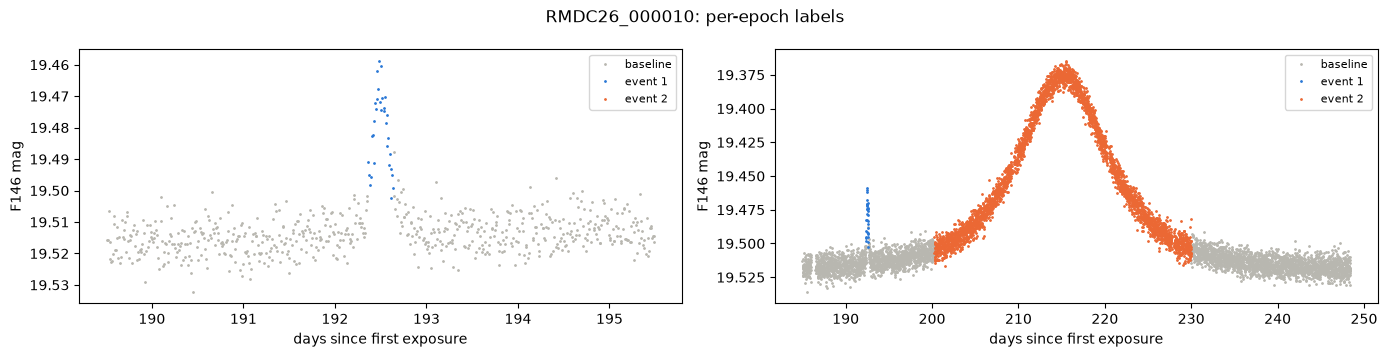

In [9]:
show = events[events.duplicated("name", keep=False)].name.iloc[0]
i, ev = names.index(show), events[events.name == show].sort_values("t0_day")
fig, axes = plt.subplots(1, len(ev), figsize=(7 * len(ev), 3.6), squeeze=False)
for ax, (_, r) in zip(axes[0], ev.iterrows()):
    w = np.abs(t - r.t0_day) < max(3, 4 * r.tE)
    for k, color in enumerate(["#b8b7b0", "#2a78d6", "#eb6834"]):
        s = w & (masks[i] == k)
        ax.plot(t[s], curves[show][0][s], ".", ms=2, color=color,
                label="baseline" if k == 0 else f"event {k}")
    ax.invert_yaxis()
    ax.set_xlabel("days since first exposure")
    ax.set_ylabel("F146 mag")
    ax.legend(fontsize=8)
fig.suptitle(f"{show}: per-epoch labels")
plt.tight_layout()
plt.show()